In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

PROJECT_DIR = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

RAW_FILE = (
    PROJECT_DIR / "data" / "raw"
    / "default of credit card clients.xls"
)

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
REPORTS_DIR = PROJECT_DIR / "reports"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_excel(RAW_FILE, header=1)

df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

target = "default_payment_next_month"

print("Dataset shape:", df.shape)
print("Target default rate:", f"{df[target].mean():.2%}")

Dataset shape: (30000, 25)
Target default rate: 22.12%


In [2]:
model_df = df.dropna(subset=[target]).copy()

X = model_df.drop(
    columns=[target, "id"],
    errors="ignore"
)

y = model_df[target].astype(int)

assert set(y.unique()).issubset({0, 1})

print("Feature matrix:", X.shape)
print("Target distribution:")
display(y.value_counts().sort_index())

print("Missing feature values:", X.isna().sum().sum())

Feature matrix: (30000, 23)
Target distribution:


default_payment_next_month
0    23364
1     6636
Name: count, dtype: int64

Missing feature values: 0


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print(f"Training default rate: {y_train.mean():.2%}")
print(f"Testing default rate:  {y_test.mean():.2%}")

Training rows: 24000
Testing rows: 6000
Training default rate: 22.12%
Testing default rate:  22.12%


In [4]:
logistic_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

print("Logistic regression trained successfully.")

Logistic regression trained successfully.


In [5]:
rf_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest trained successfully.")

Random Forest trained successfully.


In [6]:
models = {
    "Logistic Regression": logistic_model,
    "Random Forest": rf_model
}

results = []
predictions = {}

for name, model in models.items():
    y_prob = model.predict_proba(X_test)[:, 1]
    y_pred = (y_prob >= 0.5).astype(int)

    predictions[name] = {
        "probability": y_prob,
        "prediction": y_pred
    }

    results.append({
        "model": name,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "f1_score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "roc_auc": roc_auc_score(y_test, y_prob),
        "average_precision": average_precision_score(
            y_test, y_prob
        )
    })

results_df = pd.DataFrame(results).set_index("model")

display(results_df.round(4))


,accuracy,precision,recall,f1_score,roc_auc,average_precision
model,,,,,,
Logistic Regression,0.6797,0.3672,0.6202,0.4613,0.7081,0.4904
Random Forest,0.7843,0.5110,0.5765,0.5418,0.7722,0.5512


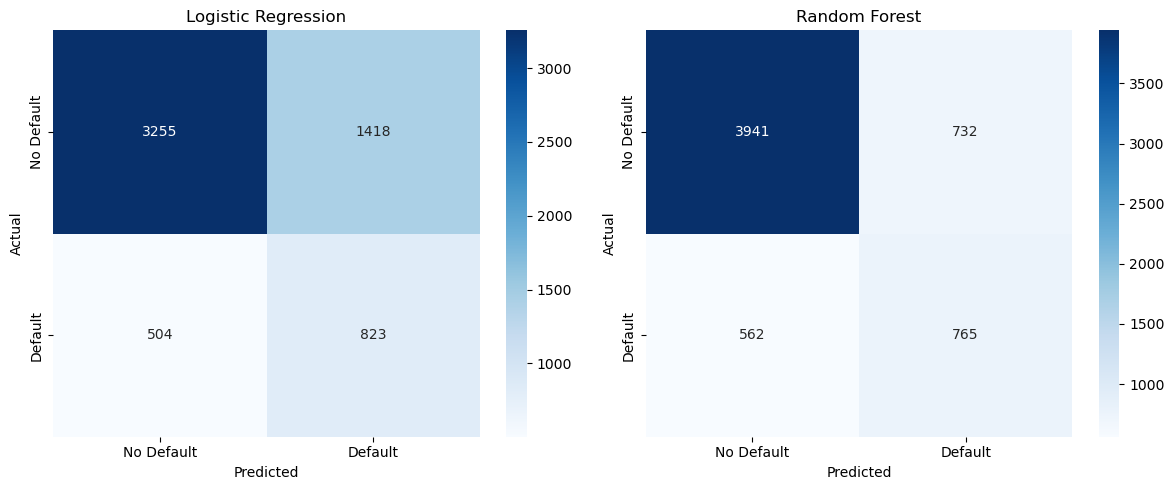

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, model_data) in zip(
    axes, predictions.items()
):
    cm = confusion_matrix(
        y_test,
        model_data["prediction"],
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax,
        xticklabels=["No Default", "Default"],
        yticklabels=["No Default", "Default"]
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

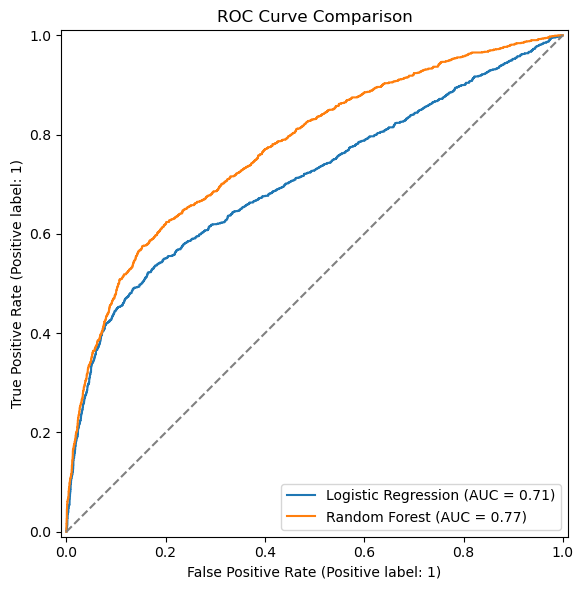

In [8]:
fig, ax = plt.subplots(figsize=(8, 6))

for name, model in models.items():
    RocCurveDisplay.from_estimator(
        model,
        X_test,
        y_test,
        name=name,
        ax=ax
    )

ax.plot([0, 1], [0, 1], linestyle="--", color="grey")
ax.set_title("ROC Curve Comparison")
plt.tight_layout()
plt.show()

In [9]:
results_df.to_csv(
    REPORTS_DIR / "model_comparison.csv"
)

# Save test predictions for subsequent analysis.
prediction_output = pd.DataFrame({
    "actual_default": y_test.to_numpy(),
    "logistic_probability": predictions[
        "Logistic Regression"
    ]["probability"],
    "logistic_prediction": predictions[
        "Logistic Regression"
    ]["prediction"],
    "random_forest_probability": predictions[
        "Random Forest"
    ]["probability"],
    "random_forest_prediction": predictions[
        "Random Forest"
    ]["prediction"]
}, index=X_test.index)

prediction_output.to_csv(
    PROCESSED_DIR / "model_test_predictions.csv",
    index_label="original_row_index"
)

print("Model evaluation outputs saved successfully.")

Model evaluation outputs saved successfully.


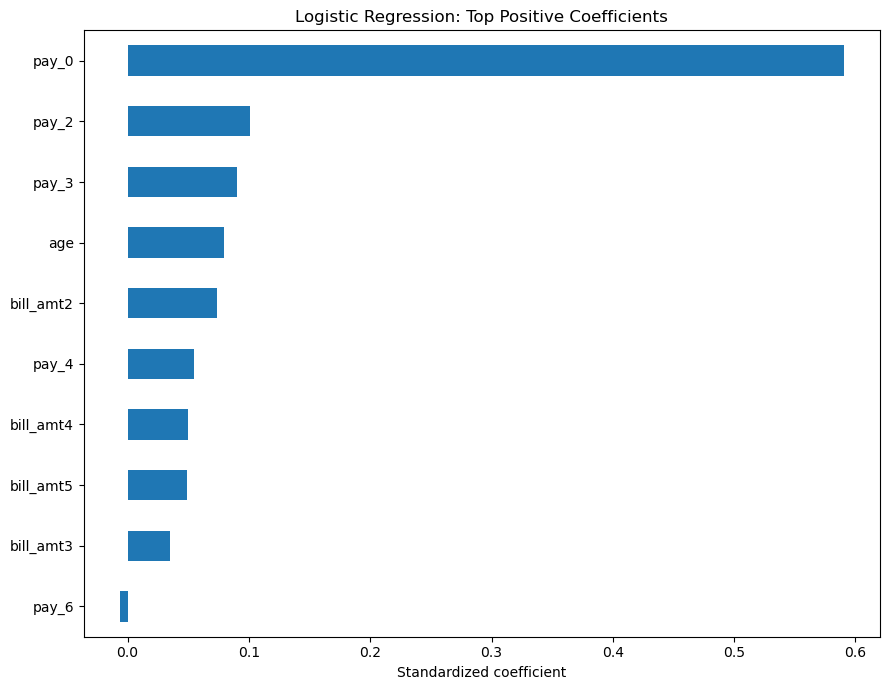

,importance
pay_0,0.145608
pay_2,0.061060
bill_amt1,0.055844
limit_bal,0.055289
pay_amt1,0.051442
pay_amt2,0.050155
bill_amt2,0.048557
pay_amt3,0.046112
bill_amt3,0.044284
bill_amt4,0.043398


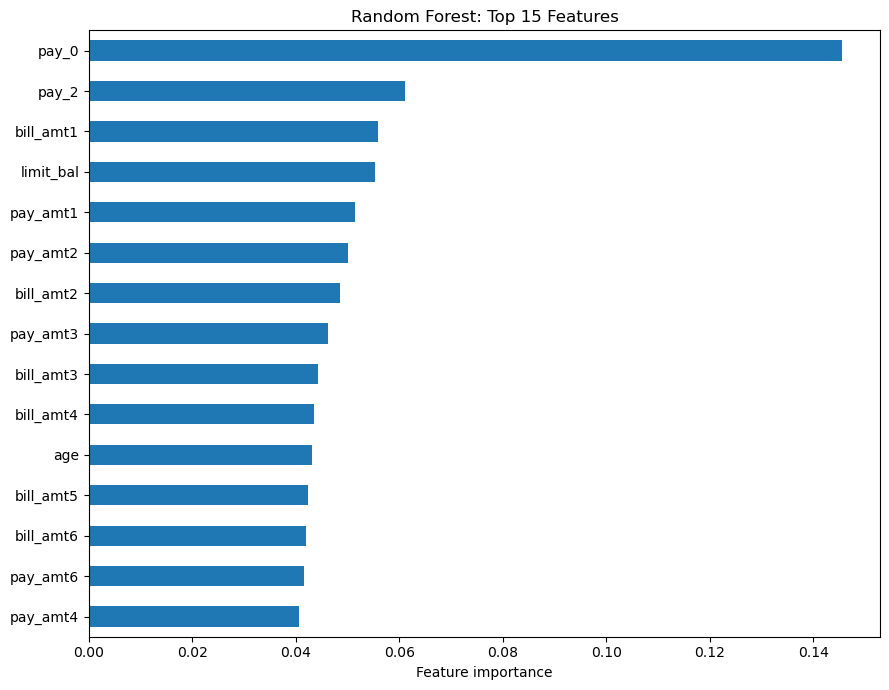

In [10]:
logistic_coefficients = pd.Series(
    logistic_model.named_steps["model"].coef_[0],
    index=X_train.columns
).sort_values()

plt.figure(figsize=(9, 7))
logistic_coefficients.tail(10).plot(kind="barh")
plt.title("Logistic Regression: Top Positive Coefficients")
plt.xlabel("Standardized coefficient")
plt.tight_layout()
plt.show()

# Random Forest feature importance
rf_importance = pd.Series(
    rf_model.named_steps["model"].feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

display(rf_importance.head(15).to_frame("importance"))

plt.figure(figsize=(9, 7))
rf_importance.head(15).sort_values().plot(kind="barh")
plt.title("Random Forest: Top 15 Features")
plt.xlabel("Feature importance")
plt.tight_layout()
plt.show()

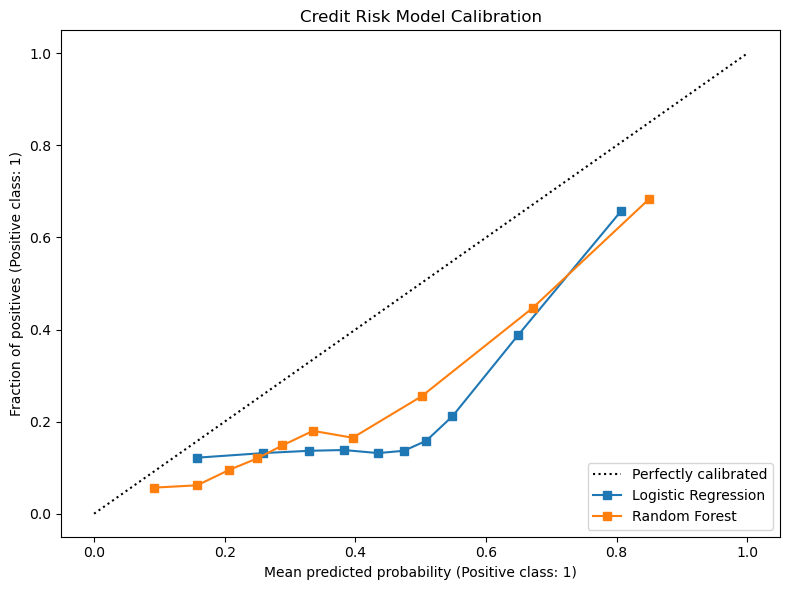

Logistic Regression Brier score: 0.2089
Random Forest Brier score: 0.1637


In [11]:
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import brier_score_loss

fig, ax = plt.subplots(figsize=(8, 6))

for name, model in models.items():
    CalibrationDisplay.from_estimator(
        model,
        X_test,
        y_test,
        n_bins=10,
        strategy="quantile",
        name=name,
        ax=ax
    )

plt.title("Credit Risk Model Calibration")
plt.tight_layout()
plt.show()

for name, model in models.items():
    probabilities = model.predict_proba(X_test)[:, 1]
    print(
        name,
        "Brier score:",
        round(brier_score_loss(y_test, probabilities), 4)
    )

In [12]:
rf_importance.rename("importance").to_csv(
    REPORTS_DIR / "random_forest_feature_importance.csv"
)

logistic_coefficients.rename("coefficient").to_csv(
    REPORTS_DIR / "logistic_regression_coefficients.csv"
)

print("Model interpretation outputs saved.")

Model interpretation outputs saved.


In [13]:
results_df = pd.read_csv(
    REPORTS_DIR / "model_comparison.csv",
    index_col=0
)

display(results_df.round(4))

,accuracy,precision,recall,f1_score,roc_auc,average_precision
model,,,,,,
Logistic Regression,0.6797,0.3672,0.6202,0.4613,0.7081,0.4904
Random Forest,0.7843,0.5110,0.5765,0.5418,0.7722,0.5512


In [14]:
from pathlib import Path

print("Saved project outputs:")
for file in sorted(Path(REPORTS_DIR).glob("*")):
    print(file.name)

Saved project outputs:
default_rate_by_credit_limit.csv
default_summary.csv
logistic_regression_coefficients.csv
model_comparison.csv
random_forest_feature_importance.csv


In [15]:
from sklearn.metrics import precision_score, recall_score, f1_score

rf_prob = predictions["Random Forest"]["probability"]

threshold_results = []

for threshold in [0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:
    rf_pred = (rf_prob >= threshold).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_test, rf_pred, zero_division=0
        ),
        "recall": recall_score(
            y_test, rf_pred, zero_division=0
        ),
        "f1_score": f1_score(
            y_test, rf_pred, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df.round(4))

,threshold,precision,recall,f1_score
0,0.25,0.2981,0.8749,0.4447
1,0.30,0.3361,0.7928,0.4721
2,0.35,0.3763,0.7167,0.4935
3,0.40,0.4261,0.6579,0.5172
4,0.45,0.4746,0.6119,0.5346
5,0.50,0.5110,0.5765,0.5418
6,0.55,0.5396,0.5290,0.5342
7,0.60,0.5747,0.4959,0.5324


In [16]:
threshold_df.to_csv(
    REPORTS_DIR / "random_forest_threshold_analysis.csv",
    index=False
)

print("Threshold analysis saved.")

Threshold analysis saved.
